# 1.1 — RQ0b: Is there a structural break in how US population growth responds to income?

For each decade d: Δln(pop)_{i,d} = α_d + β_d · ln(income per capita)_{i,d}.
States 1880–2020 (Klein, Easterlin, BEA); metros 1940–2020 (IPUMS 1940 wages, Census medians, BEA).
Break tests pool all decades with decade fixed effects (see Claude/methods/analysis-methods.md).
Findings are descriptive and associational.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from us_housing_crisis_analysis.config import PROCESSED_DATA_DIR, RQ0B_METRO_START, RQ0B_STATE_START, TABLES_DIR
from us_housing_crisis_analysis.modeling import breaks
from us_housing_crisis_analysis.plots import MUTED, SERIES_MARKERS, apply_style, save_figure

apply_style()
metro_panel = pd.read_parquet(PROCESSED_DATA_DIR / "us_metro_longrun.parquet")
panels = {
    "states": breaks.prepare_decade_panel(pd.read_parquet(PROCESSED_DATA_DIR / "us_state_longrun.parquet"), RQ0B_STATE_START),
    "metros": breaks.prepare_decade_panel(metro_panel, RQ0B_METRO_START),
}
# Robustness: 1940 metro income with missing wages left out of the denominator (not counted as 0)
metros_wages_reported = breaks.prepare_decade_panel(
    metro_panel.assign(income_pc=metro_panel.income_pc_wages_reported), RQ0B_METRO_START)
{k: (v.decade.min(), v.decade.max(), v.geo_id.nunique(), len(v)) for k, v in panels.items()}

2026-10-19 23:37:32.695 | INFO     | us_housing_crisis_analysis.config:<module>:11 - PROJ_ROOT path is: /Users/lrubin/Documents/code/US Housing Crisis Analysis


{'states': (np.int64(1880), np.int64(2010), 51, 691),
 'metros': (np.int64(1940), np.int64(2010), 386, 3070)}

## β_d by decade

,version,decade,beta,se,n
0,states,1880,0.1828,0.1096,45
1,states,1890,0.0913,0.0465,47
2,states,1900,0.1406,0.0552,48
3,states,1910,0.0832,0.0404,48
4,states,1920,0.0852,0.0472,48
5,states,1930,0.0308,0.0295,49
6,states,1940,0.1328,0.0322,49
7,states,1950,0.2756,0.0850,51
8,states,1960,0.2252,0.0727,51
9,states,1970,-0.0581,0.1188,51


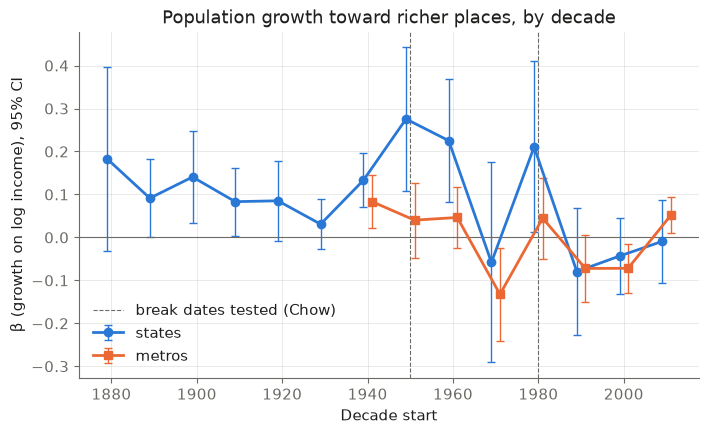

In [2]:
betas = {k: breaks.decade_betas(v) for k, v in panels.items()}
fig, ax = plt.subplots()
# states and metros are offset by a year either side of the decade start so their bars don't overlap
for (name, b), offset, marker in zip(betas.items(), (-1, 1), SERIES_MARKERS):
    ax.errorbar(b.decade + offset, b.beta, yerr=1.96 * b.se, marker=marker, capsize=3, elinewidth=1, label=name)
ax.axhline(0, color=MUTED, lw=0.8)
for d in (1950, 1980):
    ax.axvline(d, color=MUTED, ls="--", lw=0.8, label="break dates tested (Chow)" if d == 1950 else None)
ax.set(xlabel="Decade start", ylabel="β (growth on log income), 95% CI",
       title="Population growth toward richer places, by decade")
ax.legend(loc="lower left")
save_figure(fig, "rq0b_betas")
decade_betas = pd.concat(betas, names=["version"]).reset_index(level="version")
decade_betas.to_csv(TABLES_DIR / "rq0b_decade_betas.csv", index=False)
decade_betas.round(4)

## Break tests: main specification and robustness

In [3]:
rows = []
for name, dp in panels.items():
    specs = {
        "main": dp,
        "standardized income": breaks.standardize_within_decade(dp),
        "drop source-change decades": dp[~dp.decade.isin(breaks.source_change_decades(dp))],
    }
    if name == "metros":
        specs["1940 missing wages excluded"] = metros_wages_reported
    for spec, d in specs.items():
        for year in (1950, 1980):
            if d.decade.min() < year <= d.decade.max():
                r = breaks.chow_test(d, year)
                rows.append({"version": name, "spec": spec, "test": f"chow_{year}",
                             "statistic": r.statistic, "p_value": r.p_value, "breaks": ""})
        s = breaks.break_search(d)
        rows.append({"version": name, "spec": spec, "test": "break_search_bic",
                     "statistic": s.bic[s.breaks], "p_value": float("nan"),
                     "breaks": " ".join(map(str, s.breaks))})
tests = pd.DataFrame(rows)
TABLES_DIR.mkdir(parents=True, exist_ok=True)
tests.to_csv(TABLES_DIR / "rq0b_tests.csv", index=False)
tests.round(4)

,version,spec,test,statistic,p_value,breaks
0,states,main,chow_1950,0.0014,0.9697,
1,states,main,chow_1980,2.8164,0.0933,
2,states,main,break_search_bic,-2660.8739,NaN,
3,states,standardized income,chow_1950,2.1345,0.1440,
4,states,standardized income,chow_1980,13.5323,0.0002,
5,states,standardized income,break_search_bic,-2652.4224,NaN,1970
6,states,drop source-change decades,chow_1950,0.0247,0.8751,
7,states,drop source-change decades,chow_1980,3.4496,0.0633,
8,states,drop source-change decades,break_search_bic,-2235.1646,NaN,
9,metros,main,chow_1950,6.5244,0.0106,


## Sanity check against Ganong & Shoag (2017)

Ganong & Shoag find that population flowed toward high-income states from 1880 until about
1980, and that this weakened afterwards. The state-level β_d above should show the same
pattern (positive and fairly stable before 1980, lower after). If it does not, check the
pipeline before interpreting the results.

**Finding (run 2026-10-14, after the Plan 1 review fixes):** The sanity check passes. State β_d is positive in every decade from 1880 to 1960 (0.03–0.28) and is zero or negative from 1990 on (−0.08 to −0.01), the direction Ganong & Shoag report; the 1970s (negative) and 1980s (0.21) are noisy. Metro β_d is lower than the state value in 1950–1980 and close to it from 1990 on. The break tests do not pin down the timing: for states, neither Chow test rejects at 5% in the main specification (1950 p = 0.97, 1980 p = 0.09) and the BIC search picks no break, but with income standardized within decade the 1980 Chow test rejects (p < 0.001) and the search picks 1970. For metros, the 1950 Chow test rejects in every specification (p = 0.004–0.03), including with missing 1940 wages left out rather than counted as zero; but the period before 1950 is the 1940 decade alone, the only wage-only decade, so this test can't separate a change in behavior from the change of income concept. The search picks 1970, which is also when the income source switches to BEA; with the source-change decades dropped it picks 1990 and the 1980 Chow test rejects (p = 0.01). Limitations: 1940 metro income is wages only, 1950–60 metro income is a population-weighted mean of county medians, the metro panel starts in 1940, and with 14 (states) or 8 (metros) decades the break search has little power to separate 1970, 1980 and 1990.

## Annual data: when did the break happen? (Plan 1b)

BEA only, every year: states 1929–2024, metros 1969–2024. Two views:
- **Rolling β (the picture):** the decade model on ten-year windows starting every year
  (and five-year windows as a check).
- **Single break (the test):** one-year growth with year fixed effects and a slope that changes
  in year T. sup-Wald (clustered by unit) against Andrews' critical value says whether there is a
  break; T is the best-fitting year; the range comes from resampling units (checked by
  simulation) with Bai's (1997) interval alongside.

One-year slopes are about a tenth of the ten-year β; the ×10 columns put them on the decade scale.

In [4]:
from us_housing_crisis_analysis import features
from us_housing_crisis_analysis.config import (
    ENERGY_STATES_HAND, INTERIM_DATA_DIR, RQ0B_ANNUAL_END, RQ0B_ANNUAL_METRO_START,
    RQ0B_ANNUAL_STATE_START, WWII_GROWTH_YEARS,
)
from us_housing_crisis_analysis.modeling import annual_breaks as ab
from us_housing_crisis_analysis.plots import MUTED, SERIES_COLORS, SERIES_MARKERS

annual = {"states": pd.read_parquet(PROCESSED_DATA_DIR / "us_state_annual.parquet"),
          "metros": pd.read_parquet(PROCESSED_DATA_DIR / "us_metro_annual.parquet")}
energy = features.energy_states(pd.read_parquet(INTERIM_DATA_DIR / "bea.parquet"))
energy_rule = set(energy.loc[energy.energy, "state_fips"])
print("Energy states by the rule:", ", ".join(energy.loc[energy.energy, "state_name"]))
energy.head(12).round(3)

Energy states by the rule: Wyoming, West Virginia, Oklahoma, New Mexico, Louisiana, Kentucky, Texas, Alaska


,state_fips,state_name,mining_share,ratio,energy
0,56,Wyoming,0.242,11.910,True
1,54,West Virginia,0.159,7.826,True
2,40,Oklahoma,0.099,4.853,True
3,35,New Mexico,0.095,4.663,True
4,22,Louisiana,0.082,4.031,True
5,21,Kentucky,0.078,3.827,True
6,48,Texas,0.064,3.125,True
7,02,Alaska,0.061,3.015,True
8,38,North Dakota,0.056,2.736,False
9,49,Utah,0.054,2.642,False


### Rolling β by window start

In [5]:
starts = {"states": RQ0B_ANNUAL_STATE_START, "metros": RQ0B_ANNUAL_METRO_START}
rolling = {(name, h): ab.rolling_betas(p, h, starts[name], RQ0B_ANNUAL_END)
           for name, p in annual.items() for h in (10, 5)}

### Single-break tests: main specification and robustness

In [6]:
def growth(name, start=None):
    return ab.annual_growth_panel(annual[name], start or starts[name], RQ0B_ANNUAL_END)

def growth_without(name, fips):
    return ab.annual_growth_panel(features.drop_states(annual[name], fips), starts[name], RQ0B_ANNUAL_END)

runs = [  # (version, spec, growth panel, trim)
    ("states", "main", growth("states"), 0.15),
    ("states", "without energy states (rule)", growth_without("states", energy_rule), 0.15),
    ("states", "without energy states (hand list)", growth_without("states", set(ENERGY_STATES_HAND)), 0.15),
    ("states", "standardized income", breaks.standardize_within_decade(growth("states"), period="year"), 0.15),
    ("states", "without WWII years", growth("states")[lambda d: ~d.year.isin(WWII_GROWTH_YEARS)], 0.15),
    ("states", "1969-2024 only", growth("states", RQ0B_ANNUAL_METRO_START), 0.15),
    ("states", "1969-2024 only", growth("states", RQ0B_ANNUAL_METRO_START), 0.05),
    ("metros", "main", growth("metros"), 0.15),
    ("metros", "main", growth("metros"), 0.05),
    ("metros", "without energy states (rule)", growth_without("metros", energy_rule), 0.15),
    ("metros", "without energy states (hand list)", growth_without("metros", set(ENERGY_STATES_HAND)), 0.15),
    ("metros", "standardized income", breaks.standardize_within_decade(growth("metros"), period="year"), 0.15),
]

# The bootstrap range is used where its simulated coverage meets the rule; otherwise Bai's interval
coverage = []
for version in ("states", "metros"):
    dp = next(d for v, s, d, tr in runs if v == version and s == "main" and tr == 0.15)
    cov = ab.range_coverage(dp, ab.sup_wald_break(dp))
    coverage.append({"version": version, **cov})
coverage = pd.DataFrame(coverage).set_index("version")
use_bootstrap = coverage.bootstrap >= ab.COVERAGE_MIN

rows = []
for version, spec, dp, trim in runs:
    r = ab.sup_wald_break(dp, trim)
    boot = ab.bootstrap_break_year(dp, trim)
    bai = ab.bai_interval(dp, r)
    multi = ab.demeaned_break_search(dp)
    rows.append({
        "version": version, "spec": spec, "trim": trim, "break_year": r.break_year, "at_edge": r.at_edge,
        "range_low": boot.low, "range_high": boot.high, "bai_low": bai[0], "bai_high": bai[1],
        "reported_range": "bootstrap" if use_bootstrap[version] else "bai",
        "sup_wald": r.sup_wald, "sup_wald_cv5": r.critical_value,
        "beta_before_annual": r.beta_before, "beta_after_annual": r.beta_after,
        "beta_before_10y": 10 * r.beta_before, "beta_after_10y": 10 * r.beta_after,
        "multi_breaks": " ".join(map(str, multi.breaks)), "n_units": r.n_units,
        "years": f"{r.first_year}-{r.last_year}",
    })
annual_tests = pd.DataFrame(rows)
annual_tests.to_csv(TABLES_DIR / "rq0b_annual_tests.csv", index=False)
coverage.to_csv(TABLES_DIR / "rq0b_annual_range_coverage.csv")
display(coverage.round(3))
annual_tests.round(4)

,bootstrap,bai
version,,
states,0.96,0.555
metros,0.98,0.780


,version,spec,trim,break_year,at_edge,range_low,range_high,bai_low,bai_high,reported_range,sup_wald,sup_wald_cv5,beta_before_annual,beta_after_annual,beta_before_10y,beta_after_10y,multi_breaks,n_units,years
0,states,main,0.15,1990,False,1943,1990,1986,1994,bootstrap,17.8259,8.8098,0.0165,-0.0028,0.1654,-0.0282,1940 1955 1990,51,1929-2023
1,states,without energy states (rule),0.15,1970,False,1946,1990,1967,1973,bootstrap,20.3916,8.8098,0.0162,-0.0051,0.1616,-0.0513,1940 1945 1970,43,1929-2023
2,states,without energy states (hand list),0.15,1970,False,1957,1990,1967,1973,bootstrap,22.0520,8.8098,0.0156,-0.0056,0.1557,-0.0557,1940 1945 1970,43,1929-2023
3,states,standardized income,0.15,1970,False,1955,1990,1967,1973,bootstrap,41.4911,8.8098,0.0054,0.0003,0.0543,0.0032,1939 1944 1970,51,1929-2023
4,states,without WWII years,0.15,1990,False,1950,1990,1985,1995,bootstrap,12.1731,8.8098,0.0132,-0.0028,0.1322,-0.0282,1950 1955 1990,51,1929-2023
5,states,1969-2024 only,0.15,1990,False,1980,1991,1984,1996,bootstrap,2.2312,8.8098,0.0109,-0.0028,0.1088,-0.0282,1980 1989,51,1969-2023
6,states,1969-2024 only,0.05,1990,False,1980,1991,1984,1996,bootstrap,4.2022,9.8368,0.0109,-0.0028,0.1088,-0.0282,1980 1989,51,1969-2023
7,metros,main,0.15,1980,False,1978,2010,1977,1983,bootstrap,5.4765,8.8098,-0.0060,0.0035,-0.0601,0.0352,1981 1990 2007,386,1969-2023
8,metros,main,0.05,1980,False,1975,2010,1977,1983,bootstrap,5.4765,9.8368,-0.0060,0.0035,-0.0601,0.0352,1981 1990 2007,386,1969-2023
9,metros,without energy states (rule),0.15,2009,False,1977,2009,2003,2015,bootstrap,2.9858,8.8098,-0.0020,0.0049,-0.0197,0.0491,1980 1990 2007,325,1969-2023


### Where the state break-year estimates fall

Shares of the bootstrap draws at the most common years, and the Wald statistic at 1970 and at its peak for the no-energy specifications (the best-fit year and the largest Wald can differ).

In [7]:
spec_runs = {(v, s, tr): d for v, s, d, tr in runs}
for spec in ("main", "without energy states (rule)", "without energy states (hand list)"):
    dp = spec_runs[("states", spec, 0.15)]
    shares = pd.Series(ab.bootstrap_break_year(dp, 0.15).estimates).value_counts(normalize=True)
    print(f"states, {spec}: bootstrap shares", shares.head(4).round(3).to_dict())
    if spec != "main":
        r = ab.sup_wald_break(dp, 0.15)
        wald = {y: ab.wald_statistic(dp, y) for y in range(r.first_candidate, r.last_candidate + 1)}
        peak = max(wald, key=wald.get)
        print(f"    Wald at 1970 = {wald[1970]:.1f}; largest Wald = {wald[peak]:.1f} at {peak}")

states, main: bootstrap shares {1990: 0.365, 1970: 0.301, 1989: 0.102, 1943: 0.077}
states, without energy states (rule): bootstrap shares {1970: 0.525, 1990: 0.197, 1967: 0.089, 1971: 0.037}
    Wald at 1970 = 16.5; largest Wald = 20.4 at 1989


states, without energy states (hand list): bootstrap shares {1970: 0.516, 1990: 0.207, 1967: 0.09, 1965: 0.044}
    Wald at 1970 = 17.5; largest Wald = 22.1 at 1989


### Figure: rolling β with the estimated break and its range

PosixPath('/Users/lrubin/Documents/code/US Housing Crisis Analysis/reports/figures/rq0b_annual_betas.png')

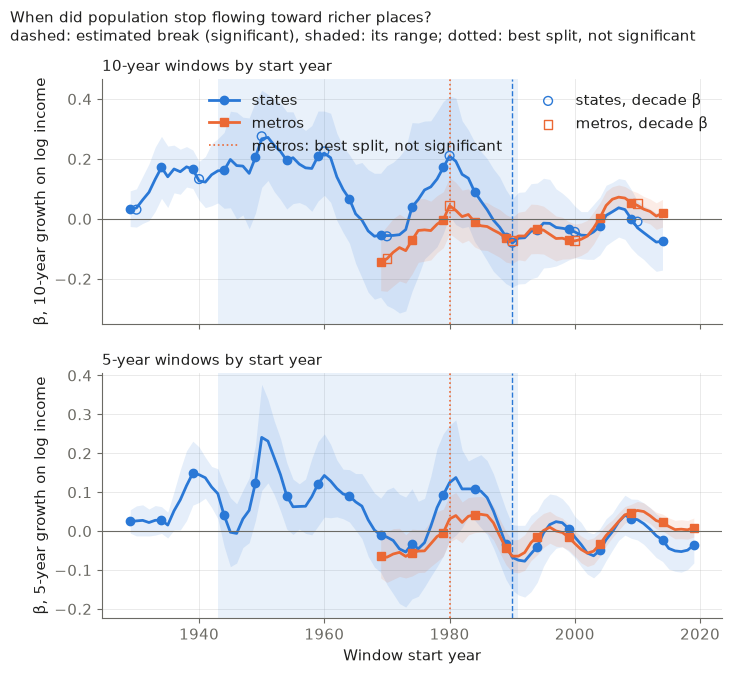

In [8]:
main = annual_tests[(annual_tests.spec == "main") & (annual_tests.trim == 0.15)].set_index("version")
fig, axes = plt.subplots(2, 1, figsize=(8, 7), sharex=True)
for ax, h in zip(axes, (10, 5)):
    for i, name in enumerate(("states", "metros")):
        b, color = rolling[(name, h)], SERIES_COLORS[i]
        ax.plot(b.start, b.beta, color=color, marker=SERIES_MARKERS[i], markevery=5, label=name)
        ax.fill_between(b.start, b.beta - 1.96 * b.se, b.beta + 1.96 * b.se, color=color, alpha=0.12, lw=0)
        m = main.loc[name]
        if m.sup_wald > m.sup_wald_cv5:  # a detected break: estimated year (dashed) and its range (shaded)
            lo, hi = (m.range_low, m.range_high) if m.reported_range == "bootstrap" else (m.bai_low, m.bai_high)
            ax.axvspan(lo, hi + 1, color=color, alpha=0.10, lw=0)
            ax.axvline(m.break_year, color=color, ls="--", lw=1)
        else:  # no break detected: show only the best-fitting split, dotted, with no range
            ax.axvline(m.break_year, color=color, ls=":", lw=1.2,
                       label=f"{name}: best split, not significant" if ax is axes[0] else None)
    ax.axhline(0, color=MUTED, lw=0.8)
    ax.set(ylabel=f"β, {h}-year growth on log income")
    ax.set_title(f"{h}-year windows by start year", loc="left", fontsize=11)
for i, (name, b) in enumerate(betas.items()):  # decade β from Plan 1, ten-year panel only
    b = b[b.decade >= starts[name]]
    axes[0].scatter(b.decade, b.beta, edgecolors=SERIES_COLORS[i], marker=SERIES_MARKERS[i], s=40,
                    facecolors="none", zorder=3, label=f"{name}, decade β")
axes[0].legend(ncols=2)
axes[1].set(xlabel="Window start year")
fig.suptitle("When did population stop flowing toward richer places?\n"
             "dashed: estimated break (significant), shaded: its range; dotted: best split, not significant",
             x=0.01, ha="left", fontsize=11)
save_figure(fig, "rq0b_annual_betas")

**Annual finding (run 2026-10-14):** **The state data show a clear break, but annual data can't pin down the year: the best fit is either about 1970 or about 1990.** Which one wins depends on the specification. With all states and raw income it is 1990. Without the energy states, or with income standardized within year (energy states included), it is 1970. The metro data, and the state data from 1969 on, find no clear single break, but those samples can't test a break before 1977 (1971 with 5% trimming).

- **Is there a break? States 1929–2024: yes.** The test statistic (sup-Wald) is 17.8, against 8.8 needed at the 5% level. On the ten-year scale, β falls from about +0.17 before the break to about −0.03 after.
- **When? States, all states:** the best fit is 1990. But when states are resampled, 37% of the draws pick 1990 and 30% pick 1970 (cell above). The 90% range runs from 1943 or earlier (1943 is the first year the test can name) to 1990. Bai's interval (1986–1994) looks much tighter, but in simulations it held the true year only 56% of the time, so it isn't used.
- **Without the energy states, the best fit moves to 1970.** This holds with both lists: the rule's eight states (Wyoming, West Virginia, Oklahoma, New Mexico, Louisiana, Kentucky, Texas, Alaska) and the hand list. About half the resampling draws pick 1970. The range is still wide (1946–1990 and 1957–1990), and the break is still clear (sup-Wald 20.4 and 22.1). The largest Wald statistic sits at 1989, but the statistic at 1970 is also well above the bar (16.5 and 17.5). β goes from about +0.16 to about −0.05.
- **Standardized income moves it to 1970 too.** With income standardized within year, and the energy states included, the best fit is also 1970 (range 1955–1990), with the strongest test statistic of all (sup-Wald 41.5). Without the WWII years, it is 1990 (range 1950–1990, sup-Wald 12.2).
- **States 1969–2024 and metros 1969–2024: no clear single break.** sup-Wald is 2.2 for states (4.2 with 5% trimming, which needs 9.8) and 5.5 for metros (needs 8.8, or 9.8 with 5% trimming). These samples can only place a break in 1977 or later (1971 or later with 5% trimming), so they can't speak to a break around 1970. The metros' best-fitting year, 1980, even has β going the other way (−0.06 to +0.04), so it shouldn't be read as a break year. In the picture, β for states rises again for windows starting around 1980 before falling. A single before/after split can't capture that within these years.
- **Several breaks allowed:** the search picks 1940, 1955 and 1990 for all states, and 1940, 1945 and 1970 without the energy states. The 1940s breaks fall in the war and early postwar years, and the 1955 break is a further shift in the 1950s. For metros it picks 1981, 1990 and 2007. Every 1929–2024 state version's later break is about 1970 or about 1990, the same two candidates.
- **How much to trust the ranges:** in simulations, the resampling range held the true year 96% of the time for states and 98% for metros. The metro figure is above the 97% target, so the metro range is on the wide side (conservative). The metro coverage is computed for the best-fitting split even though no metro break is detected, so it doesn't make the metro range a range for a break year. The simulations and the resampling both treat states (or metros) as independent of one another. Shocks that hit a whole region at once would make the true uncertainty larger than these ranges show. No point estimate falls on the first candidate year, so no "at or before" applies to the break years themselves.

**For the paper:** "Annual BEA data confirm that population growth stopped following income: richer states used to grow faster and no longer do (the ten-year β fell from about +0.17 to about −0.03). Total growth counts births and deaths as well as moves, so whether *moving* drives the change is tested separately (Plan 1c). The data can't pin down the year. The best fit is about 1990 with all states and raw income, and about 1970 without the energy states or with income standardized within year. The 90% range runs from 1943 or earlier to 1990. The samples that start in 1969 (states and metros) find no clear single break; they can test break years from 1977 on (from 1971 with 5% trimming)."

## 1970 or 1990? (Plan 1c)

The question: during 1970–89, did states behave like before 1970 or like after 1990? The
answer comes from a rule fixed before running (spec §4.1). With
`share = (β_pre − β_mid) / (β_pre − β_post)` and its 90% range from resampling states:
"1970" if low > 0 and high ≥ 1; "1990" if low ≤ 0 and high < 1; "gradual" if low > 0 and
high < 1; otherwise "can't tell". If β_pre = β_post isn't rejected at 5%, the answer is "can't
tell". The main version (annual growth with oil-year effects) sets the answer; any robustness
version that disagrees makes it "fragile".

In [9]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from us_housing_crisis_analysis import features
from us_housing_crisis_analysis.config import (
    ENERGY_STATES_HAND, GATEWAY_STATES, INTERIM_DATA_DIR, OIL_YEARS_SHORT, PROCESSED_DATA_DIR,
    RQ0B_ANNUAL_END, RQ0B_ANNUAL_STATE_START, RQ0B_CUTS, TABLES_DIR, WWII_GROWTH_YEARS,
)
from us_housing_crisis_analysis.geography import state_divisions
from us_housing_crisis_analysis.modeling import annual_breaks as ab
from us_housing_crisis_analysis.modeling import breaks
from us_housing_crisis_analysis.plots import MUTED, SERIES_COLORS, SERIES_MARKERS, save_figure

state_annual = pd.read_parquet(PROCESSED_DATA_DIR / "us_state_annual.parquet")
nm_panel = pd.read_parquet(PROCESSED_DATA_DIR / "us_state_net_migration.parquet")
energy = features.energy_states(pd.read_parquet(INTERIM_DATA_DIR / "bea.parquet"))
energy_rule = set(energy.loc[energy.energy, "state_fips"])
annual_dp = ab.annual_growth_panel(state_annual, RQ0B_ANNUAL_STATE_START, RQ0B_ANNUAL_END)
divisions = state_divisions()


def run(analysis, outcome, spec, dp, period="year", cell=None, detail=""):
    r = ab.three_period(dp, RQ0B_CUTS, period, cell)
    low, high, _ = ab.share_range(dp, RQ0B_CUTS, period, cell)
    return {"analysis": analysis, "outcome": outcome, "spec": spec, "beta_pre": r.beta_pre,
            "beta_mid": r.beta_mid, "beta_post": r.beta_post, "share": r.share, "share_low": low,
            "share_high": high, "p_pre_post": r.p_pre_post,
            "answer": ab.decide(low, high, r.p_pre_post), "detail": detail}


def without(dp, fips):
    return dp[~dp.geo_id.str[6:8].isin(set(fips))]

### Annual total growth (states 1929–2024)

In [10]:
oil = ab.oil_cells(annual_dp, energy_rule)
annual_rows = [
    run("annual", "total growth", "main: oil-year effects (rule list, 1973–1990)", oil, cell="cell"),
    run("annual", "total growth", "no oil effects", annual_dp),
    run("annual", "total growth", "oil-year effects, hand list",
        ab.oil_cells(annual_dp, set(ENERGY_STATES_HAND)), cell="cell"),
    run("annual", "total growth", "oil-year effects, 1973–1986",
        ab.oil_cells(annual_dp, energy_rule, OIL_YEARS_SHORT), cell="cell"),
    run("annual", "total growth", "within census division", ab.division_cells(annual_dp, divisions), cell="cell"),
    run("annual", "total growth", "oil-year effects, income standardized within year",
        ab.oil_cells(breaks.standardize_within_decade(annual_dp, period="year"), energy_rule), cell="cell"),
    run("annual", "total growth", "oil-year effects, without WWII years",
        oil[~oil.year.isin(WWII_GROWTH_YEARS)], cell="cell"),
]
single = ab.sup_wald_break(oil, cell="cell")
votes = pd.Series(ab.bootstrap_break_year(oil, cell="cell").estimates).value_counts(normalize=True)
print(f"Single-break search with oil-year effects: best year {single.break_year}, sup-Wald "
      f"{single.sup_wald:.1f} vs {single.critical_value:.2f}; resampling votes: "
      + ", ".join(f"{y}: {s:.0%}" for y, s in votes.head(4).items()))
pd.DataFrame(annual_rows).round(3)

Single-break search with oil-year effects: best year 1989, sup-Wald 18.5 vs 8.81; resampling votes: 1970: 37%, 1990: 26%, 1989: 15%, 1943: 7%


,analysis,outcome,spec,beta_pre,beta_mid,beta_post,share,share_low,share_high,p_pre_post,answer,detail
0,annual,total growth,"main: oil-year effects (rule list, 1973–1990)",0.017,0.009,-0.003,0.402,-0.180,1.257,0.000,can't tell,
1,annual,total growth,no oil effects,0.017,0.010,-0.003,0.350,-0.308,1.167,0.000,can't tell,
2,annual,total growth,"oil-year effects, hand list",0.017,0.008,-0.003,0.456,-0.137,1.302,0.000,can't tell,
3,annual,total growth,"oil-year effects, 1973–1986",0.017,0.010,-0.003,0.348,-0.329,1.153,0.000,can't tell,
4,annual,total growth,within census division,0.019,0.009,0.006,0.795,-1.126,2.435,0.008,can't tell,
5,annual,total growth,"oil-year effects, income standardized within year",0.005,0.001,-0.000,0.669,0.435,1.138,0.000,1970,
6,annual,total growth,"oil-year effects, without WWII years",0.014,0.009,-0.003,0.268,-0.557,1.321,0.000,can't tell,


### Figure: before 1970 vs. from 1990, the test in one picture

Blue: β for each decade on its own (states, cross-section, 95% CI), plotted at mid-decade. Orange: the
three period slopes of the annual test with year effects only (the "no oil effects" row), ×10 so both
are on the ten-year scale. The test is β_pre = β_post, clustered by state.

β_pre = β_post (annual, year effects only): per decade 0.174 vs -0.028, difference 0.203 (95% CI 0.112 to 0.294); χ²(1) = 19.0, p = 1.3e-05; 51 units, 4803 state-years
Single-break search (year effects only): best year 1990, sup-Wald 17.8 (5% critical value 8.81, 1% 12.50); search-adjusted p = 0.0008


PosixPath('/Users/lrubin/Documents/code/US Housing Crisis Analysis/reports/figures/rq0b_test.png')

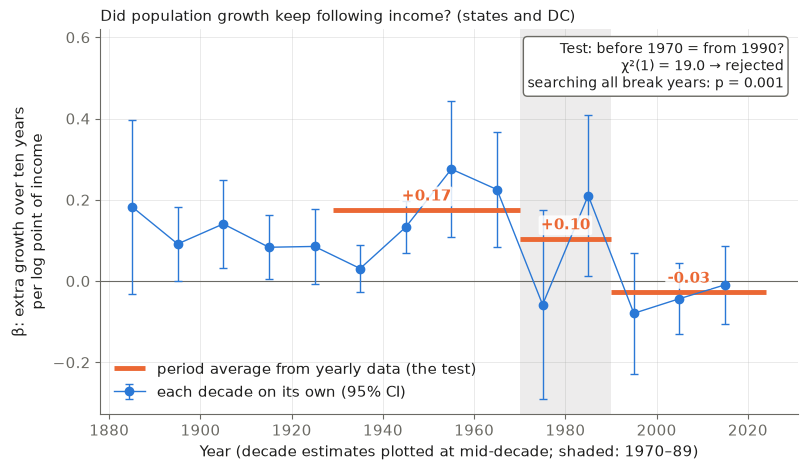

In [11]:
r = ab.three_period(annual_dp, RQ0B_CUTS, "year")
diff = r.beta_pre - r.beta_post
se = diff / r.wald_pre_post ** 0.5
print(f"β_pre = β_post (annual, year effects only): per decade {10 * r.beta_pre:.3f} vs {10 * r.beta_post:.3f}, "
      f"difference {10 * diff:.3f} (95% CI {10 * (diff - 1.96 * se):.3f} to {10 * (diff + 1.96 * se):.3f}); "
      f"χ²(1) = {r.wald_pre_post:.1f}, p = {r.p_pre_post:.1e}; {r.n_units} units, {r.n_obs} state-years")
# the cut years came from break searches on these same data, so the fixed-cut p-value is nominal;
# the sup-Wald searches every break year and its Andrews p-value pays for that search
search = ab.sup_wald_break(annual_dp)
search_p = ab.andrews_p_value(search.sup_wald, search.trim)
print(f"Single-break search (year effects only): best year {search.break_year}, sup-Wald {search.sup_wald:.1f} "
      f"(5% critical value {search.critical_value:.2f}, 1% {ab.andrews_critical_value(search.trim, 0.01):.2f}); "
      f"search-adjusted p = {search_p:.4f}")
test_stats = pd.DataFrame([  # slopes and standard errors on the ten-year scale
    ("beta_pre", 10 * r.beta_pre), ("beta_mid", 10 * r.beta_mid), ("beta_post", 10 * r.beta_post),
    ("se_pre", 10 * r.se_pre), ("se_mid", 10 * r.se_mid), ("se_post", 10 * r.se_post),
    ("difference_pre_post", 10 * diff), ("se_difference", 10 * se),
    ("ci95_low", 10 * (diff - 1.96 * se)), ("ci95_high", 10 * (diff + 1.96 * se)),
    ("wald_pre_post", r.wald_pre_post), ("p_pre_post", r.p_pre_post),
    ("p_mid_pre", r.p_mid_pre), ("p_mid_post", r.p_mid_post),
    ("sup_wald", search.sup_wald), ("sup_wald_break_year", search.break_year),
    ("sup_wald_cv5", search.critical_value), ("sup_wald_cv1", ab.andrews_critical_value(search.trim, 0.01)),
    ("sup_wald_p", search_p), ("n_units", r.n_units), ("n_obs", r.n_obs),
], columns=["statistic", "value"])
test_stats.to_csv(TABLES_DIR / "rq0b_test.csv", index=False)
sb = betas["states"]
fig, ax = plt.subplots(figsize=(9, 5))
ax.axvspan(*RQ0B_CUTS, color=MUTED, alpha=0.12, lw=0)
ax.axhline(0, color=MUTED, lw=0.8)
ax.errorbar(sb.decade + 5, sb.beta, yerr=1.96 * sb.se, color=SERIES_COLORS[0], marker="o", lw=1, capsize=3,
            elinewidth=1, label="each decade on its own (95% CI)")
spans = [(RQ0B_ANNUAL_STATE_START, RQ0B_CUTS[0]), RQ0B_CUTS, (RQ0B_CUTS[1], RQ0B_ANNUAL_END)]
for i, ((lo, hi), b) in enumerate(zip(spans, (r.beta_pre, r.beta_mid, r.beta_post))):
    ax.hlines(10 * b, lo, hi, color=SERIES_COLORS[1], lw=3.5,
              label="period average from yearly data (the test)" if i == 0 else None)
    ax.annotate(f"{10 * b:+.2f}", ((lo + hi) / 2, 10 * b), xytext=(0, 7), textcoords="offset points",
                ha="center", color=SERIES_COLORS[1], fontweight="bold",
                bbox={"boxstyle": "round,pad=0.15", "fc": "white", "ec": "none", "alpha": 0.85})
ax.text(0.98, 0.97, f"Test: before 1970 = from 1990?\nχ²(1) = {r.wald_pre_post:.1f} → rejected\n"
        f"searching all break years: p = {search_p:.3f}",
        transform=ax.transAxes, ha="right", va="top", fontsize=10,
        bbox={"boxstyle": "round", "fc": "white", "ec": MUTED})
ax.set_ylim(top=0.62)  # room for the test box above the data
ax.set(xlabel="Year (decade estimates plotted at mid-decade; shaded: 1970–89)",
       ylabel="β: extra growth over ten years\nper log point of income")
ax.set_title("Did population growth keep following income? (states and DC)", loc="left", fontsize=11)
ax.legend(loc="lower left")
save_figure(fig, "rq0b_test")

### Net migration by decade (states, 1950s–2010s)

Total growth = net migration + natural increase + census coverage change, each as a share of
the starting population. Net migration is measured directly (county estimates, summed to
states); the third part is what is left of total growth, G − M. That residual is births minus
deaths plus any change in census coverage between the two counts: nationally it sits within 5%
of NCHS births minus deaths, except in the 1970s, 1980s and 1990s (ratios 1.23, 0.91 and 1.20),
when the census undercount changed. So the β for "natural increase + census coverage change"
in those decades carries that noise. From the 1970s on, the net-migration estimates are built on
undercount-adjusted populations, so the coverage change stays out of the net-migration β. The
1950s–60s estimates use unadjusted census counts, so there the (small) coverage change sits in
net migration instead (D-30). The betas add up exactly (same states, income and decade effects).

In [12]:
nm = nm_panel[nm_panel.income_pc > 0].assign(log_income=lambda d: np.log(d.income_pc))
NATURAL = "natural increase + census coverage change"
outcomes = {"total growth": "total_rate", "net migration": "migration_rate", NATURAL: "natural_rate"}


def decade_dp(frame, col):
    return frame.assign(growth=frame[col])[["geo_id", "decade", "growth", "log_income"]]


decade_rows = [run("decade", name, "main", decade_dp(nm, col), period="decade") for name, col in outcomes.items()]
for spec, frame in {"without gateway states (CA NY NJ IL FL TX)": without(nm, GATEWAY_STATES),
                    "without energy states": without(nm, energy_rule)}.items():
    decade_rows.append(run("decade", "net migration", spec, decade_dp(frame, "migration_rate"), period="decade"))
decade_rows.append(run("decade", "net migration", "income standardized within decade",
                       breaks.standardize_within_decade(decade_dp(nm, "migration_rate")), period="decade"))
table = pd.DataFrame(annual_rows + decade_rows)
main_answer = table.answer.iloc[0]
fragile = table[(table.analysis == "annual") & (table.answer != main_answer)].spec.tolist()
table.loc[0, "detail"] = "fragile: " + "; ".join(fragile) if fragile else "robust across the annual checks"
table.to_csv(TABLES_DIR / "rq0b_1970_vs_1990.csv", index=False)
print("Answer (main):", main_answer, "|", table.loc[0, "detail"])
# context (spec §4.1): the main versions' β's per decade (annual ×10) and the Wald tests on β_mid
context = [("annual total growth, oil-year effects", ab.three_period(oil, RQ0B_CUTS, "year", "cell"), 10)]
context += [(f"decade {name}", ab.three_period(decade_dp(nm, col), RQ0B_CUTS, "decade"), 1)
            for name, col in outcomes.items()]
for label, r, scale in context:
    print(f"{label}: β per decade {scale * r.beta_pre:.3f} / {scale * r.beta_mid:.3f} / "
          f"{scale * r.beta_post:.3f}; Wald p: mid = pre {r.p_mid_pre:.3f}, mid = post {r.p_mid_post:.3f}")
table.round(3)

Answer (main): can't tell | fragile: oil-year effects, income standardized within year
annual total growth, oil-year effects: β per decade 0.174 / 0.093 / -0.028; Wald p: mid = pre 0.325, mid = post 0.161
decade total growth: β per decade 0.320 / 0.096 / -0.047; Wald p: mid = pre 0.000, mid = post 0.189
decade net migration: β per decade 0.291 / 0.065 / -0.058; Wald p: mid = pre 0.000, mid = post 0.136
decade natural increase + census coverage change: β per decade 0.029 / 0.031 / 0.012; Wald p: mid = pre 0.956, mid = post 0.650


,analysis,outcome,spec,beta_pre,beta_mid,beta_post,share,share_low,share_high,p_pre_post,answer,detail
0,annual,total growth,"main: oil-year effects (rule list, 1973–1990)",0.017,0.009,-0.003,0.402,-0.180,1.257,0.000,can't tell,"fragile: oil-year effects, income standardized..."
1,annual,total growth,no oil effects,0.017,0.010,-0.003,0.350,-0.308,1.167,0.000,can't tell,
2,annual,total growth,"oil-year effects, hand list",0.017,0.008,-0.003,0.456,-0.137,1.302,0.000,can't tell,
3,annual,total growth,"oil-year effects, 1973–1986",0.017,0.010,-0.003,0.348,-0.329,1.153,0.000,can't tell,
4,annual,total growth,within census division,0.019,0.009,0.006,0.795,-1.126,2.435,0.008,can't tell,
5,annual,total growth,"oil-year effects, income standardized within year",0.005,0.001,-0.000,0.669,0.435,1.138,0.000,1970,
6,annual,total growth,"oil-year effects, without WWII years",0.014,0.009,-0.003,0.268,-0.557,1.321,0.000,can't tell,
7,decade,total growth,main,0.320,0.096,-0.047,0.612,0.340,1.230,0.000,1970,
8,decade,net migration,main,0.291,0.065,-0.058,0.646,0.378,1.084,0.000,1970,
9,decade,natural increase + census coverage change,main,0.029,0.031,0.012,-0.066,-3.882,3.426,0.654,can't tell,


### Where the change comes from: moving vs. the rest (natural increase + census coverage change)

,level,label,beta_total,beta_migration,beta_natural
0,decade,1950,0.3509,0.3217,0.0292
1,decade,1960,0.2736,0.2441,0.0295
2,decade,1970,-0.0314,-0.0322,0.0008
3,decade,1980,0.2516,0.1846,0.0671
4,decade,1990,-0.0822,-0.0932,0.0110
5,decade,2000,-0.0476,-0.0498,0.0022
6,decade,2010,-0.0117,-0.0337,0.0220
7,period,before (1950s–60s),0.3203,0.2910,0.0294
8,period,middle (1970s–80s),0.0957,0.0652,0.0305
9,period,after (1990s–),-0.0468,-0.0584,0.0116


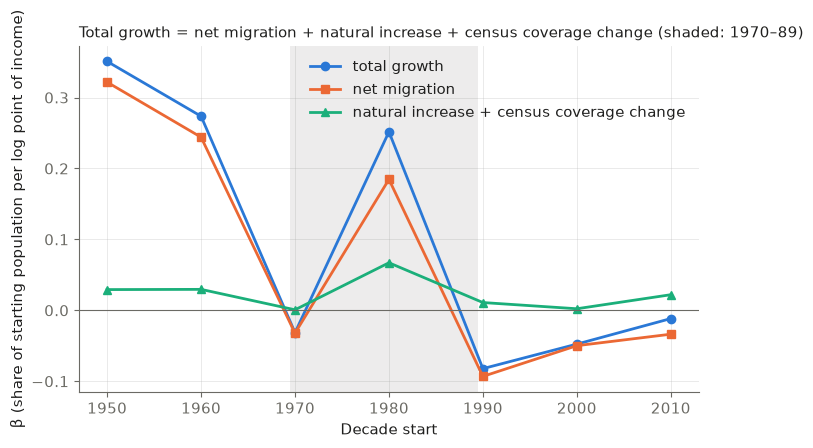

In [13]:
split = []
by_decade = {name: breaks.decade_betas(decade_dp(nm, col), period="decade").set_index("decade").beta
             for name, col in outcomes.items()}
for d in by_decade["total growth"].index:
    split.append({"level": "decade", "label": str(d), "beta_total": by_decade["total growth"][d],
                  "beta_migration": by_decade["net migration"][d], "beta_natural": by_decade[NATURAL][d]})
main_decade = {r["outcome"]: r for r in decade_rows[:3]}
for part, key in (("before (1950s–60s)", "beta_pre"), ("middle (1970s–80s)", "beta_mid"), ("after (1990s–)", "beta_post")):
    split.append({"level": "period", "label": part, "beta_total": main_decade["total growth"][key],
                  "beta_migration": main_decade["net migration"][key],
                  "beta_natural": main_decade[NATURAL][key]})
split = pd.DataFrame(split)
assert np.allclose(split.beta_total, split.beta_migration + split.beta_natural)
split.to_csv(TABLES_DIR / "rq0b_growth_split.csv", index=False)

fig, ax = plt.subplots()
for i, name in enumerate(outcomes):
    b = by_decade[name]
    ax.plot(b.index, b.values, color=SERIES_COLORS[i], marker=SERIES_MARKERS[i], label=name)
ax.axvspan(1969.5, 1989.5, color=MUTED, alpha=0.12, lw=0)
ax.axhline(0, color=MUTED, lw=0.8)
ax.set(xlabel="Decade start", ylabel="β (share of starting population per log point of income)")
ax.set_title("Total growth = net migration + natural increase + census coverage change (shaded: 1970–89)",
             loc="left", fontsize=11)
ax.legend()
save_figure(fig, "rq0b_growth_split")
split.round(4)

### Influence: leaving out one state at a time (added after review, 2026-10-19)

Not one of the preset checks, so it doesn't change the rule's answers. For the main annual version, the annual version without oil effects (the class report's test) and the two main decade versions, each state is left out in turn and the rule re-run (999 draws each).

In [14]:
KEY = ["analysis", "outcome", "spec"]
names = state_annual.drop_duplicates("geo_id").set_index("geo_id").geo_name


def drop_one(geo_id):
    a, n = annual_dp[annual_dp.geo_id != geo_id], nm[nm.geo_id != geo_id]
    return [run("annual", "total growth", "main: oil-year effects (rule list, 1973–1990)",
                ab.oil_cells(a, energy_rule), cell="cell"),
            run("annual", "total growth", "no oil effects", a),
            run("decade", "total growth", "main", decade_dp(n, "total_rate"), period="decade"),
            run("decade", "net migration", "main", decade_dp(n, "migration_rate"), period="decade")]


loo = pd.DataFrame([dict(x, left_out=g) for g in sorted(annual_dp.geo_id.unique()) for x in drop_one(g)])
loo = loo.merge(table[KEY + ["share", "answer"]], on=KEY, suffixes=("", "_full"))
loo.drop(columns="detail").to_csv(TABLES_DIR / "rq0b_leave_one_out.csv", index=False)
summary = loo.groupby(KEY, sort=False).apply(lambda g: pd.Series({
    "answer (all states)": g.answer_full.iloc[0], "share (all states)": g.share_full.iloc[0],
    "share range over left-out states": f"{g.share.min():.2f} to {g.share.max():.2f}",
    "max p_pre_post": g.p_pre_post.max(),
    "answer changes when leaving out": ", ".join(names[g.left_out[g.answer != g.answer_full]]) or "none",
    "without DC": f"{g.share[g.left_out == 'state:11'].iloc[0]:.2f} → {g.answer[g.left_out == 'state:11'].iloc[0]}",
}), include_groups=False)
summary

answer (all states)  \
analysis outcome       spec                                                                
annual   total growth  main: oil-year effects (rule list, 1973–1990)          can't tell   
                       no oil effects                                         can't tell   
decade   total growth  main                                                         1970   
         net migration main                                                         1970   

                                                                      share (all states)  \
analysis outcome       spec                                                                
annual   total growth  main: oil-year effects (rule list, 1973–1990)            0.402458   
                       no oil effects                                           0.350076   
decade   total growth  main                                                     0.611811   
         net migration main                                                     0.646182   

                                                                     share range over left-out states  \
analysis outcome       spec                                                                             
annual   total growth  main: oil-year effects (rule list, 1973–1990)                     0.07 to 0.68   
                       no oil effects                                                    0.01 to 0.65   
decade   total growth  main                                                              0.52 to 0.77   
         net migration main                                                              0.56 to 0.79   

                                                                      max p_pre_post  \
analysis outcome       spec                                                            
annual   total growth  main: oil-year effects (rule list, 1973–1990)        0.000173   
                       no oil effects                                       0.000170   
decade   total growth  main                                                 0.000454   
         net migration main                                                 0.000007   

                                                                     answer changes when leaving out  \
analysis outcome       spec                                                                            
annual   total growth  main: oil-year effects (rule list, 1973–1990)            District of Columbia   
                       no oil effects                                           District of Columbia   
decade   total growth  main                                                     District of Columbia   
         net migration main                                                     District of Columbia   

                                                                          without DC  
analysis outcome       spec                                                           
annual   total growth  main: oil-year effects (rule list, 1973–1990)     0.07 → 1990  
                       no oil effects                                    0.01 → 1990  
decade   total growth  main                                           0.52 → gradual  
         net migration main                                           0.56 → gradual

**Review update (2026-10-19).** Two results added after an outside review change how this answer reads:
- **The p-value below is nominal.** The 1970 and 1990 cuts came from break searches on these same data. The single-break search over every year (year effects only, cell 23) gives sup-Wald 17.8 at 1990; its Andrews p-value, which pays for the search, is 0.0008 (1% critical value 12.50). So a change is still clearly there, with p ≈ 0.001 rather than 1e-5.
- **The decade "1970" rests on DC.** Leaving out one state at a time (cell above), DC is the only state that changes any answer, and it changes all four: decade total growth and net migration become "gradual" (shares 0.52 and 0.56), and both annual versions become "1990" (shares 0.07 and 0.01). Without DC the middle-period slope is about as high as before 1970 on annual data. The pre-vs-post rejection survives every single-state drop (largest p 0.0005).

**Answer (run 2026-10-15): can't tell, and the answer is fragile.** In the main version (annual total growth, states 1929–2024, with oil-year effects), 1970–89 had moved 40% of the way from "before" toward "after" (share 0.40), but the 90% range runs from −0.18 to 1.26. The rule therefore can't separate 1970, 1990 and a gradual slide.

- **The overall change is real.** β_pre = β_post is rejected (nominal p < 0.001; search-adjusted p ≈ 0.001, see the review update). On the ten-year scale, growth followed income with β 0.17 before 1970, 0.09 in 1970–89 and −0.03 from 1990. The last is not different from zero (year effects only: −0.028, SE 0.047): growth stopped following income, but richer states did not clearly grow slower. But 1970–89 isn't significantly different from either side (Wald p = 0.32 against before, 0.16 against after; cell above).
- **Fragile: one annual check disagrees.**
  - With income standardized within year, the answer is "1970" (share 0.67, range 0.43–1.14).
  - The other five checks also give "can't tell":
    - no oil effects: 0.35 (−0.31 to 1.17);
    - hand list: 0.46 (−0.14 to 1.30);
    - 1973–1986 oil window: 0.35 (−0.33 to 1.15);
    - within census division: 0.79 (−1.13 to 2.44);
    - without the WWII years: 0.27 (−0.56 to 1.32).
  - The oil-year effects barely move the share (0.35 without them, 0.40 with them).
  - Within census divisions, the point estimate for β after 1990 stays slightly positive (+0.06 on the ten-year scale), but not significantly (p = 0.46). So the data can't say whether, within their own region, richer states still grew a little faster.
- **The decade data give "1970", for growth and for moving alike.**
  - **Total growth:** growth followed income with a decade β of 0.32 in the 1950s–60s, 0.10 in the 1970s–80s and −0.05 from the 1990s. Share 0.61 (0.34–1.23): "1970".
  - **Net migration followed income** with β 0.29, 0.07 and −0.06. Share 0.65 (0.38–1.08): "1970". 1970–89 differs clearly from before (p < 0.001) but not from after (p = 0.14).
  - All three net-migration checks also give "1970":
    - without the gateway states CA, NY, NJ, IL, FL and TX: 0.64 (0.36–1.15);
    - without the energy states: 0.64 (0.32–1.16);
    - income standardized within decade: 0.73 (0.55–1.05).
  - So the immigration-gateway states don't drive the moving result.
  - But none of these checks leaves out DC, and leaving out DC gives "gradual" (review update). The decade "1970" is therefore not robust.
- **Why annual and decade data differ.** The two tests define "before" differently.
  - In the decade data, "before" is only the 1950s and 1960s, when β was highest (0.35 and 0.27).
  - In the annual data, "before" is 1929–69, which includes the Depression and war years, when β was lower. On the ten-year scale it averages 0.17.
  - The middle period is also not one regime. The decade β is −0.03 in the 1970s, already like "after", and +0.25 in the 1980s, back near "before". The share averages over that rebound.
  - The two tests also use different growth measures (one-year log growth vs. ten-year percent change, D-30). The share has no units, so both read the same way.
- **Where the change comes from: moving.**
  - Total β falls by 0.37 from before to after. Net migration accounts for 0.35 (95%). Natural increase + census coverage change accounts for 0.02 (5%).
  - From before to the middle, total β falls 0.22, all of it in net migration. Natural increase + census coverage change is flat: 0.029, 0.031, 0.012, with no significant change (p = 0.65).
  - That third part is total growth minus net migration. In the 1970s–90s it carries census coverage noise: nationally it differs from NCHS births minus deaths by the ratios 1.23, 0.91 and 1.20. Its β for those decades is therefore not pure births minus deaths. From the 1970s on, net migration is built on undercount-adjusted populations, so the coverage change sits in this third part and not in net migration. The 1950s–60s net-migration estimates use unadjusted census counts, so there the coverage change sits in net migration. It is small (the national undercount fell about 0.7M in the 1950s and 0.1M in the 1960s), and if anything it lowers net migration's β before 1970, which works against "1970". In the 1980s, a natural increase rebuilt from the file's own adjusted populations matches NCHS (ratio 1.005), and the coverage part's β is −0.0003, so the 1980s rise is not coverage (D-30).
- **Single-break search with oil-year effects** (descriptive, not part of the rule):
  - The best year is 1989, with sup-Wald 18.5 (critical value 8.81).
  - Resampling votes: 1970 37%, 1990 26%, 1989 15%, 1943 7%. Without oil effects, Plan 1b had 1990 37% and 1970 30%.
  - The oil terms move votes toward 1970 but don't settle the year: 1989 and 1990 together still take 41%.

**For the paper:** "Population growth followed income across states before 1970 and had stopped doing so by 1990: on the ten-year scale the slope fell from 0.17 to about zero (−0.03, not significantly different from zero). The change is significant even after allowing for the search over break years (p ≈ 0.001). When it happened is not settled. Annual data can't separate 1970, 1990 and a gradual slide; decade data point to 1970, but only with DC in the sample, and without DC they point to a gradual change. The 1970–89 middle is itself uneven: a 1970s drop and a 1980s rebound. In decade data from 1950, estimated net migration carries about 95% of the drop from the 1950s–60s to the 1990s–2010s (ten-year percent change, not log growth)."
